<a href="https://colab.research.google.com/github/Kartikey-Paliwal/dna-gene-family-classifier/blob/main/01_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import pandas as pd
import kagglehub

path = kagglehub.dataset_download("nageshsingh/dna-sequence-dataset")

human = pd.read_table(os.path.join(path, "human.txt"))
chimp = pd.read_table(os.path.join(path, "chimpanzee.txt"))
dog   = pd.read_table(os.path.join(path, "dog.txt"))

print(human.shape)
print(human.head())

100%|██████████| 1.51M/1.51M [00:00<00:00, 2.71MB/s]

Extracting files...


(4380, 2)
                                            sequence  class
0  ATGCCCCAACTAAATACTACCGTATGGCCCACCATAATTACCCCCA...      4
1  ATGAACGAAAATCTGTTCGCTTCATTCATTGCCCCCACAATCCTAG...      4
2  ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...      3
3  ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...      3
4  ATGCAACAGCATTTTGAATTTGAATACCAGACCAAAGTGGATGGTG...      3


In [2]:
seq = human["sequence"][0]
print(len(seq))
print(seq[:100])

207
ATGCCCCAACTAAATACTACCGTATGGCCCACCATAATTACCCCCATACTCCTTACACTATTCCTCATCACCCAACTAAAAATATTAAACACAAACTACC


## Day2: Data Exploration

In [3]:
class_names = {
    0: "G protein-coupled receptors",
    1: "Tyrosine kinase",
    2: "Tyrosine phosphatase",
    3: "Synthetase",
    4: "Synthase",
    5: "Ion channel",
    6: "Transcription factor"
}

human["family"] = human["class"].map(class_names)
human.head()

,sequence,class,family
0,ATGCCCCAACTAAATACTACCGTATGGCCCACCATAATTACCCCCA...,4,Synthase
1,ATGAACGAAAATCTGTTCGCTTCATTCATTGCCCCCACAATCCTAG...,4,Synthase
2,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3,Synthetase
3,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3,Synthetase
4,ATGCAACAGCATTTTGAATTTGAATACCAGACCAAAGTGGATGGTG...,3,Synthetase


family
Transcription factor           1343
Synthase                        711
Synthetase                      672
Tyrosine kinase                 534
G protein-coupled receptors     531
Tyrosine phosphatase            349
Ion channel                     240
Name: count, dtype: int64


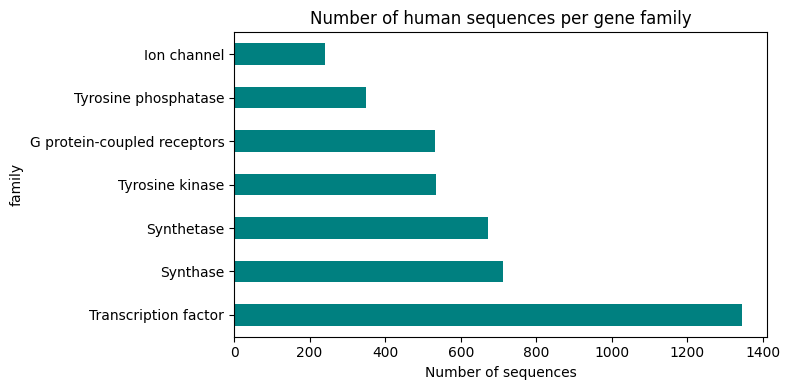

In [4]:
import matplotlib.pyplot as plt

counts = human["family"].value_counts()
print(counts)

counts.plot(kind="barh", figsize=(8, 4), color="teal")
plt.title("Number of human sequences per gene family")
plt.xlabel("Number of sequences")
plt.tight_layout()
plt.show()

count     4380.000000
mean      1263.598630
std       1280.754087
min          5.000000
25%        405.000000
50%        865.000000
75%       1662.000000
max      18921.000000
Name: length, dtype: float64


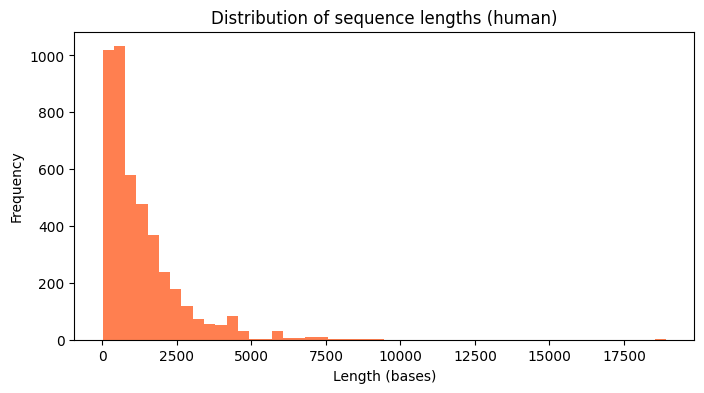

In [5]:
human["length"] = human["sequence"].str.len()

print(human["length"].describe())

human["length"].plot(kind="hist", bins=50, figsize=(8, 4), color="coral")
plt.title("Distribution of sequence lengths (human)")
plt.xlabel("Length (bases)")
plt.show()

Lengths range from 5 to 18,921; median 865
Distribution is right-skewed (most short, few very long)
Very short sequences may be errors, to be checked
Different lengths are why k-mers are needed

In [6]:
print(human.groupby("family")["length"].median().sort_values())

family
Synthase                        622.0
Synthetase                      658.5
Transcription factor            870.0
Tyrosine phosphatase            940.0
G protein-coupled receptors    1104.0
Tyrosine kinase                1137.0
Ion channel                    1579.5
Name: length, dtype: float64


                             Human  Chimp    Dog
class                                           
G protein-coupled receptors  0.121  0.139  0.160
Tyrosine kinase              0.122  0.110  0.091
Tyrosine phosphatase         0.080  0.086  0.078
Synthetase                   0.153  0.136  0.116
Synthase                     0.162  0.155  0.165
Ion channel                  0.055  0.065  0.073
Transcription factor         0.307  0.310  0.317


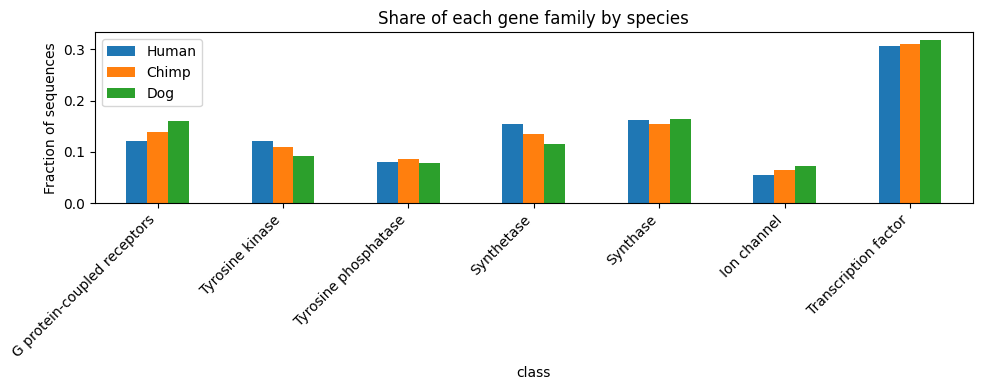

In [7]:
comparison = pd.DataFrame({
    "Human": human["class"].value_counts(normalize=True),
    "Chimp": chimp["class"].value_counts(normalize=True),
    "Dog":   dog["class"].value_counts(normalize=True),
}).sort_index()

comparison.index = comparison.index.map(class_names)
print(comparison.round(3))

comparison.plot(kind="bar", figsize=(10, 4))
plt.title("Share of each gene family by species")
plt.ylabel("Fraction of sequences")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [8]:
dupes = human.duplicated(subset="sequence").sum()
print("Exact duplicate sequences:", dupes)

Exact duplicate sequences: 751


In [9]:
print("Before:", len(human))

human_clean = human.drop_duplicates(subset="sequence")
human_clean = human_clean[human_clean["length"] >= 50]

print("After:", len(human_clean))
print(human_clean["family"].value_counts())

Before: 4380
After: 3606
family
Transcription factor           1100
Synthase                        586
Synthetase                      568
G protein-coupled receptors     443
Tyrosine kinase                 404
Tyrosine phosphatase            291
Ion channel                     214
Name: count, dtype: int64


In [10]:
def get_kmers(sequence, k):
    kmers = []
    for i in range(len(sequence) - k + 1):
        kmers.append(sequence[i:i+k])
    return kmers

print(get_kmers("ATGCAT", 3))

['ATG', 'TGC', 'GCA', 'CAT']


In [11]:
for k in [3, 4, 5, 6, 8]:
    print(k, "→", 4**k, "possible k-mers")

3 → 64 possible k-mers
4 → 256 possible k-mers
5 → 1024 possible k-mers
6 → 4096 possible k-mers
8 → 65536 possible k-mers


In [12]:
human_clean["kmers"] = human_clean["sequence"].apply(lambda s: get_kmers(s, 6))

print(human_clean["kmers"].iloc[0][:10])
print("Number of 6-mers in first sequence:", len(human_clean["kmers"].iloc[0]))

['ATGCCC', 'TGCCCC', 'GCCCCA', 'CCCCAA', 'CCCAAC', 'CCAACT', 'CAACTA', 'AACTAA', 'ACTAAA', 'CTAAAT']
Number of 6-mers in first sequence: 202


In [13]:
from collections import Counter

tf = human_clean[human_clean["family"] == "Transcription factor"]
all_kmers = [kmer for kmers in tf["kmers"] for kmer in kmers]

print(Counter(all_kmers).most_common(10))

[('CAGCAG', 2416), ('AGCAGC', 1903), ('AGAAGA', 1902), ('GCAGCA', 1721), ('GAAGAA', 1688), ('AAGAAG', 1624), ('CCAGCA', 1466), ('GGAGGA', 1441), ('AAGAAA', 1428), ('GAGGAG', 1412)]


## Day 4: Vectorizing


In [14]:
human_clean["text"] = human_clean["kmers"].apply(lambda k: " ".join(k))
print(human_clean["text"].iloc[0][:100])

ATGCCC TGCCCC GCCCCA CCCCAA CCCAAC CCAACT CAACTA AACTAA ACTAAA CTAAAT TAAATA AAATAC AATACT ATACTA TA


In [15]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer()
X = cv.fit_transform(human_clean["text"])

print(X.shape)

(3606, 4466)


 3606 - Rows
 4466 - column

In [17]:
vocab = cv.get_feature_names_out()
print("Vocabulary size:", len(vocab))
print("First 10 k-mers:", vocab[:10])

row = X[0].toarray()[0]
print("Non-zero k-mers in sequence 1:", (row > 0).sum())

Vocabulary size: 4466
First 10 k-mers: ['aaaaaa' 'aaaaac' 'aaaaag' 'aaaaat' 'aaaaca' 'aaaacc' 'aaaacg' 'aaaact'
 'aaaaga' 'aaaagc']
Non-zero k-mers in sequence 1: 183


In [18]:
density = X.nnz / (X.shape[0] * X.shape[1])
print("Fraction of non-zero cells:", round(density, 3))

Fraction of non-zero cells: 0.185


In [19]:
y = human_clean["class"].values
print(X.shape[0], len(y))

3606 3606


 ## Day 5: First model

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape[0], "sequences")
print("Test: ", X_test.shape[0], "sequences")

Train: 2884 sequences
Test:  722 sequences


In [21]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

model = MultinomialNB()
model.fit(X_train, y_train)

train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc  = accuracy_score(y_test,  model.predict(X_test))

print("Train accuracy:", round(train_acc, 3))
print("Test accuracy: ", round(test_acc, 3))

Train accuracy: 0.638
Test accuracy:  0.578


In [23]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
print("Baseline accuracy:", round(dummy.score(X_test, y_test), 3))

Baseline accuracy: 0.305


In [24]:
preds = model.predict(X_test[:10])

for true, pred in zip(y_test[:10], preds):
    print(f"True: {class_names[true]:30} Predicted: {class_names[pred]}")

True: Synthase                       Predicted: Synthase
True: Transcription factor           Predicted: Transcription factor
True: Synthase                       Predicted: Tyrosine kinase
True: Synthetase                     Predicted: Synthetase
True: Synthetase                     Predicted: Synthetase
True: Synthetase                     Predicted: Tyrosine phosphatase
True: Transcription factor           Predicted: Transcription factor
True: Tyrosine kinase                Predicted: Tyrosine kinase
True: Synthase                       Predicted: Tyrosine phosphatase
True: Transcription factor           Predicted: Transcription factor


## Day 6: Evaluation

In [25]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test)
names = [class_names[i] for i in range(7)]

print(classification_report(y_test, y_pred, target_names=names))

                             precision    recall  f1-score   support

G protein-coupled receptors       0.77      0.62      0.69        89
            Tyrosine kinase       0.40      0.65      0.50        81
       Tyrosine phosphatase       0.23      0.52      0.32        58
                 Synthetase       0.68      0.64      0.66       114
                   Synthase       0.53      0.50      0.52       117
                Ion channel       0.76      0.60      0.68        43
       Transcription factor       0.91      0.55      0.69       220

                   accuracy                           0.58       722
                  macro avg       0.61      0.58      0.58       722
               weighted avg       0.67      0.58      0.60       722



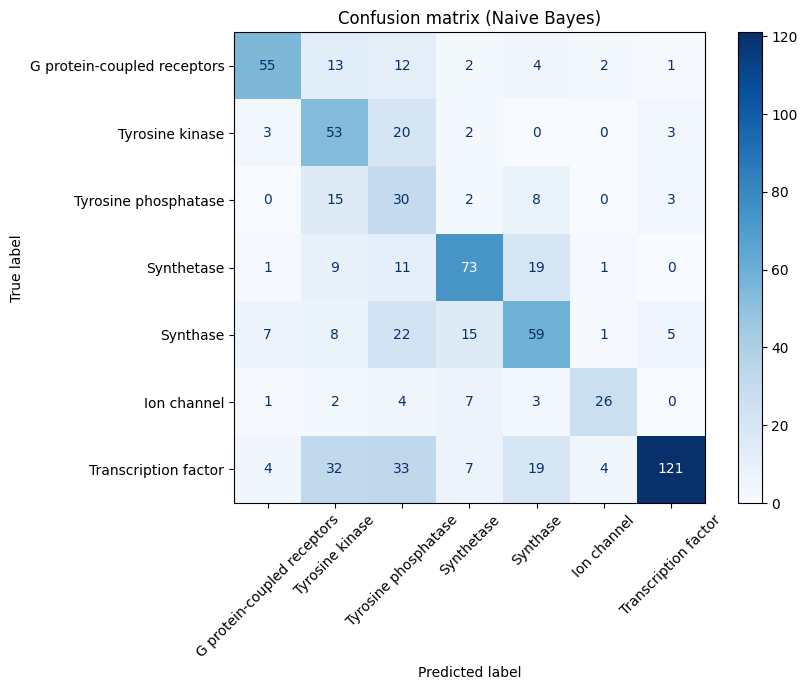

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=names,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)
plt.title("Confusion matrix (Naive Bayes)")
plt.tight_layout()
plt.show()

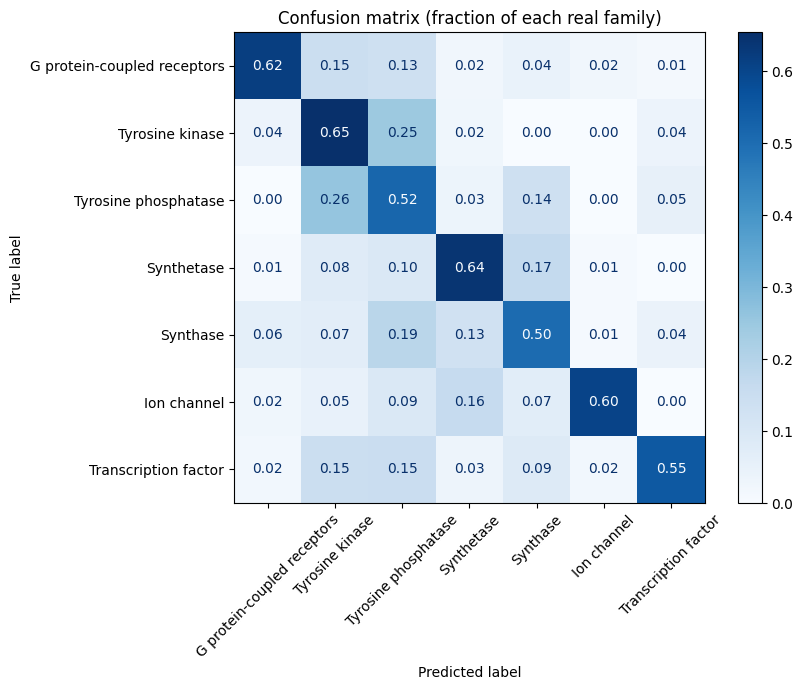

In [27]:
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=names,
    normalize="true",
    values_format=".2f",
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)
plt.title("Confusion matrix (fraction of each real family)")
plt.tight_layout()
plt.show()

0.65 → 65% of real kinases were correctly called kinase
0.25 → 25% were wrongly called tyrosine phosphatase
the rest are small mistakes spread around